# The Question of Experience

*The Mathematics of Machine Intelligence · Chapter 32*

Work the numbers behind the tests that try to detect experience, and see what each can and cannot show.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask what the signal is, what ties it to reports of experience in known cases, whether the tie transfers to the new case, and which rival explanations were tested. For a negative result, ask for the test's sensitivity before reading the silence. For a score, ask how its cutoff was chosen. For a machine, say that no test of experience has been validated against reports for any machine.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 32, The Question of Experience: executable mathematics and reader-facing teaching content."""
import math
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def binary_entropy(p):
    """H(p) in bits; the terms 0 x log 0 are taken to be 0."""
    if p < 0 or p > 1:
        raise ValueError('p must lie between 0 and 1.')
    if p in (0, 1):
        return 0.0
    return -p * math.log2(p) - (1 - p) * math.log2(1 - p)

def complexity_score(new_patterns, length, share_on):
    """C = c log2(n) / (n H(p)); None when p is 0 or 1, where H(p) = 0."""
    h = binary_entropy(share_on)
    if h == 0:
        return None
    return new_patterns * math.log2(length) / (length * h)
CELLS = 32

def bits_text(h):
    return f'{sig(h)} bit' if abs(h - 1) < 1e-12 else f'{sig(h)} bits'

def pci_picture(new_patterns=4, on_cells=16):
    p = on_cells / CELLS
    h = binary_entropy(p)
    score = complexity_score(new_patterns, CELLS, p)
    fig, ax = panels()
    stereo = complexity_score(4, CELLS, 0.5)
    varied = complexity_score(7, CELLS, 0.5)
    labels = ['stereotyped\n(4 new, half on)', 'varied\n(7 new, half on)', 'your setting']
    values = [stereo, varied, score if score is not None else 0.0]
    colours = [GREY, TEAL, NAVY if score is not None else 'white']
    bars = ax[0].bar(labels, values, color=colours, width=0.6, edgecolor=NAVY if score is None else 'none')
    for bar, v, i in zip(bars, values, range(3)):
        if i == 2 and score is None:
            tag(ax[0], bar.get_x() + bar.get_width() / 2, 0.08, 'undefined\n(no mix of\nones and zeros)', va='bottom', color=TERRA)
        else:
            tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 0.03, sig(v), va='bottom')
    ax[0].axhline(1, color=GREY, linestyle='dotted', linewidth=1)
    ax[0].set(ylabel='score C', title='Two hypothetical responses and yours', ylim=(0, 3.0))
    ax[0].tick_params(axis='x', labelsize=8)
    grid = np.linspace(0, 20, 81)
    for cells_on, style, colour in [(8, 'dashed', GOLD), (16, 'solid', TEAL)]:
        curve = [complexity_score(c, CELLS, cells_on / CELLS) for c in grid]
        chosen = cells_on == on_cells
        ax[1].plot(grid, curve, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.8, label=f'{cells_on} of 32 cells on')
    if score is not None:
        ring(ax[1], new_patterns, score)
    else:
        tag(ax[1], 13, 0.5, 'selected mix:\nscore undefined', color=TERRA)
    ax[1].axhline(1, color=GREY, linestyle='dotted', linewidth=1)
    ax[1].set(xlabel='new patterns counted (c)', ylabel='score C', title='More new patterns, higher score', ylim=(0, 3.0), xlim=(0, 20))
    ax[1].legend(fontsize=9, loc='upper left')
    needed = CELLS * h / math.log2(CELLS) if h > 0 else None
    metrics = {'Share of cells on': sig(p), 'Entropy H(p) (bits)': sig(h), 'Score C': sig(score) if score is not None else 'undefined (H = 0: all cells on or all off)', 'New patterns for a score of 1': sig(needed) if needed is not None else 'undefined (H = 0)'}
    if score is None:
        summary = 'With every cell on or every cell off, the entropy is zero and the score divides by zero, so it is undefined. The formula needs both ones and zeros present.'
        calc = f'p = {on_cells}/32 = {sig(p)}, so H(p) = 0 and C = c x 5 / (32 x 0) has no value.'
    else:
        summary = f'With {new_patterns:g} new patterns and {on_cells} of 32 cells on, the entropy is {bits_text(h)} and the score is {sig(score)}. At this mix, a score of 1 would take {sig(needed)} new patterns.'
        calc = f'p = {on_cells}/32 = {sig(p)}, H(p) = {bits_text(h)}. C = c log2(n) / (n H(p)) = {new_patterns:g} x 5 / (32 x {sig(h)}) = {sig(score)}. The score is 1 when c = 32 x {sig(h)} / 5 = {sig(needed)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def lempel_ziv_count(bits):
    """Number of new patterns in the Lempel-Ziv (1976) exhaustive parse, by the Kaspar-Schuster scan."""
    s = list(bits)
    n = len(s)
    if n < 2:
        return n
    i, k, l, k_max, c = (0, 1, 1, 1, 1)
    while True:
        if s[i + k - 1] == s[l + k - 1]:
            k += 1
            if l + k > n:
                c += 1
                break
        else:
            if k > k_max:
                k_max = k
            i += 1
            if i == l:
                c += 1
                l += k_max
                if l + 1 > n:
                    break
                i, k, k_max = (0, 1, 1)
            else:
                k = 1
    return c

def score_of_string(bits):
    n = len(bits)
    p = sum(bits) / n
    return complexity_score(lempel_ziv_count(bits), n, p)

def repeated_string(share, length):
    pattern = '01' if share == 0.5 else '00001'
    return [int(ch) for ch in (pattern * length)[:length]]

@lru_cache(maxsize=None)
def random_string_scores(length, share, trials=200):
    """Scores of seeded random strings with each cell on with chance `share`. Strings with no mix are skipped."""
    rng = np.random.default_rng([32, length, int(round(share * 100))])
    out = []
    for _ in range(trials):
        bits = (rng.random(length) < share).astype(int)
        value = score_of_string(bits.tolist())
        if value is not None:
            out.append(value)
    return np.array(out)
LENGTHS = [8, 16, 32, 64, 128, 256, 512, 1024]

def lz_picture(length=32, share=0.5):
    scores = random_string_scores(length, share)
    mean = float(scores.mean())
    low, high = (float(v) for v in np.percentile(scores, [10, 90]))
    repeat_bits = repeated_string(share, length)
    repeat = score_of_string(repeat_bits)
    repeat_share = sum(repeat_bits) / length
    repeat_label = 'repeating string\n(01 pattern,\nhalf on)' if share == 0.5 else f'repeating string\n(00001 pattern,\n{sig(repeat_share, 3)} on)'
    fig, ax = panels()
    for other, style, colour in [(0.5, 'solid', TEAL), (0.2, 'dashed', GOLD)]:
        means = [random_string_scores(n, other).mean() for n in LENGTHS]
        chosen = other == share
        ax[0].plot(LENGTHS, means, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.8, marker='o' if chosen else None, markersize=4, label=f'random strings, {other:g} of cells on')
        if chosen:
            lows = [np.percentile(random_string_scores(n, other), 10) for n in LENGTHS]
            highs = [np.percentile(random_string_scores(n, other), 90) for n in LENGTHS]
            ax[0].fill_between(LENGTHS, lows, highs, color=NAVY, alpha=0.12, linewidth=0)
    ax[0].axhline(1, color=GREY, linestyle='dotted', linewidth=1)
    ring(ax[0], length, mean)
    ax[0].set_xscale('log', base=2)
    ax[0].set_xticks(LENGTHS)
    ax[0].set_xticklabels([str(n) for n in LENGTHS], fontsize=8)
    ax[0].set(xlabel='string length (cells)', ylabel='mean score C', title='Random strings settle toward 1, slowly', ylim=(0.8, 2.3))
    ax[0].legend(fontsize=8, loc='upper right')
    spread = float(scores.max() - scores.min())
    off_scale = float(scores.min()) - repeat > 3 * spread
    ax[1].hist(scores, bins=18, color=TEAL, alpha=0.8, edgecolor='white')
    top = ax[1].get_ylim()[1]
    if off_scale:
        ax[1].set_xlim(float(scores.min()) - 0.6 * spread, float(scores.max()) + 0.3 * spread)
        tag(ax[1], ax[1].get_xlim()[0] + 0.03 * spread, top * 0.8, f"repeating string\n({('01' if share == 0.5 else '00001')}, {sig(repeat_share, 3)} on)\nscores {sig(repeat)},\noff the left edge", color=TERRA, ha='left', fontsize=9)
    else:
        ax[1].axvline(repeat, color=TERRA, linewidth=2.5, linestyle='dashed')
        tag(ax[1], repeat, top * 0.72, repeat_label, color=TERRA, ha='left' if repeat < mean else 'right', fontsize=9)
    ax[1].axvline(1, color=GREY, linestyle='dotted', linewidth=1)
    ax[1].set(xlabel='score C of one string', ylabel='strings out of 200', title=f'{length} cells: 200 random strings (seeded)')
    metrics = {'Mean score, random strings': sig(mean), 'Middle 80 percent of scores': f'{sig(low)} to {sig(high)}', 'Score of a repeating string': sig(repeat), 'Share of random strings scoring above 1': sig(float((scores > 1).mean()))}
    summary = f'At {length} cells with a chance {share:g} that a cell is on, 200 seeded random strings average a score of {sig(mean)}; the repeating string, with {sig(repeat_share, 3)} of its cells on, scores {sig(repeat)}. Short random strings score above 1, and the average falls toward 1 only slowly as strings lengthen.'
    calc = f"Each string: c = Lempel-Ziv count of new patterns, p = its share of ones, C = c log2({length}) / ({length} x H(p)). Seeds are fixed by length and mix. The repeating string is {('01 repeated' if share == 0.5 else '00001 repeated')} to {length} cells (its share of ones is {sig(repeat_share, 4)}, {('exactly 0.5' if share == 0.5 else 'not exactly 0.2')})."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
STUDIES = {'Casarotto and colleagues': [('Casarotto: complex response\nin patients with reflexive\nbehavior only', 'Casarotto: 9/43', 9, 43), ('Casarotto: above the cutoff\nin minimally conscious\npatients', 'Casarotto: 36/38', 36, 38)], 'Bodien and colleagues': [('Bodien: fMRI or EEG response,\nno bedside response', 'Bodien: 60/241', 60, 241), ('Bodien: fMRI or EEG response,\nbedside response', 'Bodien: 43/112', 43, 112)], 'Monti and colleagues': [('Monti: patients who could\nmodulate brain activity', 'Monti: 5/54', 5, 54), ("Monti: healthy volunteers'\nanswers decoded correctly", 'Monti: 48/48', 48, 48)]}
Z_VALUES = {0.9: 1.645, 0.95: 1.96, 0.99: 2.576}

def wilson_interval(successes, total, z=1.96):
    """Wilson score interval for a share. The companion's own addition, not reported by the studies."""
    if total <= 0 or successes < 0 or successes > total:
        raise ValueError('Need 0 <= successes <= total and total > 0.')
    p = successes / total
    denom = 1 + z * z / total
    centre = (p + z * z / (2 * total)) / denom
    half = z * math.sqrt(p * (1 - p) / total + z * z / (4 * total * total)) / denom
    return (max(0.0, centre - half), min(1.0, centre + half))

def counts_picture(study='Casarotto and colleagues', level=0.95):
    z = Z_VALUES[level]
    groups = STUDIES[study]
    fig, ax = panels()
    for row, (label, _short, k, n) in enumerate(groups):
        y = 1 - row
        ax[0].barh([y], [k], color=TEAL, height=0.5)
        ax[0].barh([y], [n - k], left=[k], color=GREY, alpha=0.45, height=0.5)
        ax[0].text(n * 1.02, y, f'{k} of {n}', va='center', fontsize=10, color=NAVY)
    ax[0].set_yticks([1, 0])
    ax[0].set_yticklabels([g[0] for g in groups], fontsize=8)
    biggest = max((g[3] for g in groups))
    ax[0].set(xlabel='people (or answers); teal is the reported count', title='The counts as reported', xlim=(0, biggest * 1.3), ylim=(-0.6, 1.6))
    row_y = 0
    ticks, names = ([], [])
    all_groups = [(s, g) for s, gs in STUDIES.items() for g in gs]
    for s, (label, short, k, n) in reversed(all_groups):
        low, high = wilson_interval(k, n, z)
        chosen = s == study
        colour = NAVY if chosen else GREY
        ax[1].plot([low, high], [row_y, row_y], color=colour, linewidth=3 if chosen else 1.6)
        ax[1].plot([k / n], [row_y], marker='o', color=colour, markersize=7 if chosen else 5)
        ticks.append(row_y)
        names.append(short)
        row_y += 1
    ax[1].set_yticks(ticks)
    ax[1].set_yticklabels(names, fontsize=8)
    ax[1].xaxis.label.set_fontsize(9)
    ax[1].set(xlabel=f"share, with a {int(level * 100)} percent Wilson interval\n(illustrative, companion's own: sampling noise only, samples not random)", title='Counts of different sizes carry different doubt', xlim=(0, 1.02))
    metrics = {}
    for label, short, k, n in groups:
        low, high = wilson_interval(k, n, z)
        name = short.split(': ')[1]
        metrics[f'Share, {short}'] = sig(k / n)
        metrics[f'Interval, {short}'] = f'{sig(low)} to {sig(high)}'
    (la, sa, ka, na), (lb, sb, kb, nb) = groups
    lowa, higha = wilson_interval(ka, na, z)
    lowb, highb = wilson_interval(kb, nb, z)
    summary = f"{sa} is a share of {sig(ka / na)} with an interval of {sig(lowa)} to {sig(higha)}; {sb} is {sig(kb / nb)}, interval {sig(lowb)} to {sig(highb)}. The interval is the companion's own and covers sampling noise only, under an independence assumption these samples do not meet."
    calc = f'Wilson interval at z = {z:g}: centre (p + z^2/2n)/(1 + z^2/n), half-width z sqrt(p(1-p)/n + z^2/4n^2)/(1 + z^2/n). For {ka} of {na}: p = {sig(ka / na)}, interval {sig(lowa)} to {sig(higha)}. For {kb} of {nb}: p = {sig(kb / nb)}, interval {sig(lowb)} to {sig(highb)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
MEASURED_SECONDS = {3: 1.0, 5: 16.0, 7: 2.75 * 3600}

def order_cost(n):
    """The order of the cost the source note gives, n^5 3^n. Relative units, not seconds."""
    return n ** 5 * 3 ** n

def seconds_text(seconds):
    return f'{seconds:.0f}'

def time_text(seconds):
    if seconds >= 3600:
        return f'{sig(seconds / 3600)} hours'
    return f'{sig(seconds)} second' if abs(seconds - 1) < 1e-12 else f'{sig(seconds)} seconds'

def iit_time_picture(gates=7):
    seconds = MEASURED_SECONDS[gates]
    fig, ax = panels()
    sizes = [3, 5, 7]
    bars = ax[0].bar([str(n) for n in sizes], [MEASURED_SECONDS[n] for n in sizes], color=[NAVY if n == gates else GREY for n in sizes], width=0.55)
    for bar, n in zip(bars, sizes):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, MEASURED_SECONDS[n] * 1.5, {3: '1 s', 5: '16 s', 7: '2.75 h'}[n], va='bottom')
    ax[0].set_yscale('log')
    ax[0].set_ylim(0.5, 200000.0)
    ax[0].set_yticks([1, 10, 100, 1000.0, 10000.0, 100000.0])
    ax[0].set_yticklabels(['1 s', '10 s', '100 s', '1000 s', '10,000 s', '100,000 s'])
    ax[0].annotate('about 16 times', xy=(1, 14), xytext=(0.45, 90), fontsize=9, color=DARK_GOLD, arrowprops={'arrowstyle': '->', 'color': DARK_GOLD}, ha='center')
    ax[0].annotate('about 600 times', xy=(2, 6000), xytext=(1.15, 600), fontsize=9, color=DARK_GOLD, arrowprops={'arrowstyle': '->', 'color': DARK_GOLD}, ha='center')
    ax[0].set(xlabel='gates in the ring', ylabel='reported run time (log scale)', title='Reported times, 32 processor cores')
    grid = np.arange(3, 12.01, 0.25)
    ax[1].plot(grid, [order_cost(n) / order_cost(3) for n in grid], color=TEAL, linewidth=2, label='order n^5 3^n, relative to 3 gates')
    ax[1].plot(sizes, [MEASURED_SECONDS[n] / MEASURED_SECONDS[3] for n in sizes], linestyle='none', marker='s', color=TERRA, markersize=7, label='reported time, relative to 3 gates')
    ax[1].axvspan(10, 12, color=GOLD, alpha=0.18, linewidth=0)
    ax[1].text(11, 3, 'stated practical\nlimit, 10 to 12', ha='center', fontsize=8, color=DARK_GOLD)
    ring(ax[1], gates, MEASURED_SECONDS[gates] / MEASURED_SECONDS[3])
    ax[1].set_yscale('log')
    ax[1].set(xlabel='gates', ylabel='cost relative to 3 gates (log scale)', title='Cost climbs steeply with size', xlim=(2.7, 12.3))
    ax[1].legend(fontsize=8, loc='upper left')
    previous = {3: None, 5: 3, 7: 5}[gates]
    if previous is None:
        ratio_text = 'undefined (3 gates is the smallest ring reported)'
        formula_text = 'undefined (smallest ring reported)'
    else:
        ratio_text = sig(seconds / MEASURED_SECONDS[previous])
        formula_text = sig(order_cost(gates) / order_cost(previous))
    metrics = {'Reported time': time_text(seconds), 'Times longer than the previous ring': ratio_text, "Order formula's growth over the previous ring": formula_text, 'Reported time in seconds': seconds_text(seconds)}
    if previous is None:
        summary = 'Three gates took about 1 second, the smallest ring reported, so there is no earlier ring to compare it with. Larger rings are on the other bars.'
        calc = 'Reported time for a ring of 3 majority gates: about 1 second on 32 cores.'
    else:
        summary = f'A ring of {gates} gates took about {time_text(seconds)}, {sig(seconds / MEASURED_SECONDS[previous])} times the {previous}-gate time. The order formula n^5 3^n gives {sig(order_cost(gates) / order_cost(previous))} times for the same step, so the formula and the timings differ step by step.'
        calc = f'{gates} gates: {seconds_text(seconds)} s; {previous} gates: {seconds_text(MEASURED_SECONDS[previous])} s; ratio {sig(seconds / MEASURED_SECONDS[previous])}. Formula ratio = ({gates}/{previous})^5 x 3^({gates - previous}) = {sig(order_cost(gates) / order_cost(previous))}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def recurrent_adder(inputs):
    """One unit with a feedback wire: its state is the running total. Returns the states and the output."""
    state, states = (0, [])
    for x in inputs:
        state = state + x
        states.append(state)
    return (states, state)

def unrolled_adder(inputs):
    """A feed-forward chain: one separate unit per input, each passing its total to the next unit."""

    def make_unit(x):
        return lambda previous: previous + x
    chain = [make_unit(x) for x in inputs]
    value, values = (0, [])
    for unit in chain:
        value = unit(value)
        values.append(value)
    return (values, value)

def bits_of(index, length=4):
    return [index >> length - 1 - k & 1 for k in range(length)]

def unfolding_picture(sequence=11):
    inputs = bits_of(sequence)
    states, out_r = recurrent_adder(inputs)
    values, out_u = unrolled_adder(inputs)
    fig, ax = panels()
    a = ax[0]
    a.set_xlim(0, 10)
    a.set_ylim(0, 8)
    a.axis('off')
    a.set_title('Same inputs, two different wirings', fontsize=11)
    a.text(0.1, 7.2, 'inputs', fontsize=9, color=GREY, va='center')
    for k, x in enumerate(inputs):
        tag(a, 3.0 + 1.9 * k, 7.2, str(x), fontsize=11)
    a.add_patch(plt.Rectangle((0.1, 4.3), 1.7, 1.4, facecolor='white', edgecolor=TEAL, linewidth=2.2))
    a.text(0.95, 5.0, 'one unit\nwith feedback', ha='center', va='center', fontsize=8.5, color=TEAL)
    a.annotate('', xy=(0.5, 5.7), xytext=(1.4, 5.7), arrowprops={'arrowstyle': '->', 'connectionstyle': 'arc3,rad=1.3', 'color': TEAL, 'linewidth': 1.4})
    a.annotate('', xy=(2.55, 5.0), xytext=(1.8, 5.0), arrowprops={'arrowstyle': '->', 'color': TEAL, 'linewidth': 1.2})
    a.text(0.1, 3.75, 'total after each input', fontsize=8, color=GREY)
    for k, v in enumerate(states):
        a.add_patch(plt.Circle((3.0 + 1.9 * k, 5.0), 0.5, facecolor='white', edgecolor=TEAL, linewidth=2))
        a.text(3.0 + 1.9 * k, 5.0, str(v), ha='center', va='center', fontsize=11, color=TEAL)
    for k, v in enumerate(values):
        a.add_patch(plt.Rectangle((2.45 + 1.9 * k, 1.2), 1.1, 1.1, facecolor='white', edgecolor=TERRA, linewidth=2))
        a.text(3.0 + 1.9 * k, 1.75, str(v), ha='center', va='center', fontsize=11, color=TERRA)
        if k < 3:
            a.annotate('', xy=(2.45 + 1.9 * (k + 1), 1.75), xytext=(3.55 + 1.9 * k, 1.75), arrowprops={'arrowstyle': '->', 'color': TERRA, 'linewidth': 1.4})
    a.text(0.1, 1.75, 'four units\nin a row', fontsize=8.5, color=TERRA, va='center')
    a.text(0.1, 0.5, 'output: recurrent ' + str(out_r) + ', chain ' + str(out_u), fontsize=9.5, color=NAVY)
    outputs_r = [recurrent_adder(bits_of(i))[1] for i in range(16)]
    outputs_u = [unrolled_adder(bits_of(i))[1] for i in range(16)]
    totals = list(range(5))
    count_r = [outputs_r.count(t) for t in totals]
    count_u = [outputs_u.count(t) for t in totals]
    x = np.arange(5)
    ax[1].bar(x - 0.17, count_r, width=0.34, color=TEAL, label='one unit with feedback')
    ax[1].bar(x + 0.17, count_u, width=0.34, color=TERRA, label='chain of four units')
    ring(ax[1], out_r, count_r[out_r])
    for xi, c in zip(x, count_r):
        tag(ax[1], xi, c + 0.4, str(c), va='bottom', fontsize=9)
    ax[1].set_xticks(x)
    agree = sum((r == u for r, u in zip(outputs_r, outputs_u)))
    ax[1].set(xlabel='output (the total)', ylabel='input sequences giving it', title=f'All 16 sequences: {agree} of 16 agree', ylim=(0, 8.2))
    ax[1].legend(fontsize=8, loc='upper right')
    metrics = {'Inputs': ' '.join((str(v) for v in inputs)), 'Output, one unit with feedback': out_r, 'Output, chain of four': out_u, 'Sequences where they agree': f'{agree} of 16'}
    summary = f"For inputs {' '.join((str(v) for v in inputs))} the feedback unit's total runs {', '.join((str(v) for v in states))} and the chain gives the same, ending at {out_r}. The two agree on all {agree} of 16 sequences, yet one has a single unit and a feedback wire and the other has four units in a row."
    calc = f"Recurrent: state = state + input, giving {', '.join((str(v) for v in states))}. Unrolled: unit k adds input k to the total from unit k - 1, giving {', '.join((str(v) for v in values))}. The outputs {out_r} and {out_u} match; so do the other {agree - 1} sequences."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def missed_share(flag_rate, sensitivity):
    """m = r(1 - s) / (s (1 - r)); None with a reason when the conditions fail."""
    r, s = (flag_rate, sensitivity)
    if not s > 0:
        return (None, 'sensitivity must be above zero')
    if not 0 < r < 1:
        return (None, 'the flag rate must be above zero and below one')
    if r > s + 1e-12:
        return (None, 'the flag rate cannot exceed the sensitivity, since the test never flags a case without the property')
    return (r * (1 - s) / (s * (1 - r)), '')

def miss_picture(flag_rate=0.1, sensitivity=0.5):
    m, reason = missed_share(flag_rate, sensitivity)
    fig, ax = panels()
    if m is None:
        ax[0].axis('off')
        shown = 'undefined\n\n' + reason.replace('the flag rate cannot exceed the sensitivity, since the test never flags a case without the property', 'the flag rate cannot exceed\nthe sensitivity, since the test\nnever flags a case that\nlacks the property')
        ax[0].text(0.5, 0.5, shown, ha='center', va='center', fontsize=9.5, color=TERRA, transform=ax[0].transAxes)
        has, missed, flagged, negatives = (None, None, flagged_n(flag_rate), 100 * (1 - flag_rate))
    else:
        has = 100 * flag_rate / sensitivity
        flagged = 100 * flag_rate
        missed = has - flagged
        negatives = 100 * (1 - flag_rate)
        ax[0].barh([1], [flagged], color=TEAL, height=0.5, label='flagged (have it)')
        ax[0].barh([1], [missed], left=[flagged], color=TERRA, height=0.5, label='have it, missed')
        ax[0].barh([1], [100 - has], left=[has], color=GREY, alpha=0.45, height=0.5, label='do not have it')
        ax[0].barh([0], [missed], color=TERRA, height=0.5)
        ax[0].barh([0], [negatives - missed], left=[missed], color=GREY, alpha=0.45, height=0.5)
        if flagged > 6:
            ax[0].text(flagged / 2, 1, sig(flagged), ha='center', va='center', color='white', fontsize=9)
        if missed > 6:
            ax[0].text(flagged + missed / 2, 1, sig(missed), ha='center', va='center', color='white', fontsize=9)
        if missed > 6:
            ax[0].text(missed / 2, 0, sig(missed), ha='center', va='center', color='white', fontsize=9)
        ax[0].set_yticks([1, 0])
        ax[0].set_yticklabels(['all 100 cases', 'the negatives only'])
        ax[0].set(xlabel='cases out of 100', title='Where the misses sit', xlim=(0, 100))
        ax[0].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    grid = np.linspace(0.02, 1, 197)
    for rate, style, colour in [(0.05, 'dotted', GREY), (0.1, 'solid', TEAL), (0.25, 'dashed', GOLD), (0.5, 'dashdot', DARK_GOLD)]:
        xs = [s for s in grid if s >= rate]
        ys = [missed_share(rate, s)[0] for s in xs]
        chosen = rate == flag_rate
        ax[1].plot(xs, ys, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'flag rate {rate:g}')
    if m is not None:
        ring(ax[1], sensitivity, m)
    else:
        tag(ax[1], 0.3, 0.5, 'selected sensitivity\nis below the flag rate', color=TERRA, fontsize=9)
    ax[1].set(xlabel='sensitivity (s)', ylabel='share of negatives that have it (m)', title='A low flag rate can hide many misses', ylim=(-0.02, 1.05), xlim=(0, 1.02))
    ax[1].legend(fontsize=8, loc='upper right')
    if m is None:
        metrics = {'Cases with the property (of 100)': 'undefined', 'Missed by the test': 'undefined', 'Negatives': sig(100 * (1 - flag_rate)), 'Share of negatives that have it (m)': 'undefined (' + reason + ')'}
        summary = f'At flag rate {flag_rate:g} and sensitivity {sensitivity:g} the share is undefined: {reason}. Raise the sensitivity to at least the flag rate to see a value.'
        calc = f'm = r(1 - s) / (s(1 - r)) needs s above 0, r between 0 and 1, and r no larger than s; here r = {flag_rate:g} and s = {sensitivity:g}.'
    else:
        metrics = {'Cases with the property (of 100)': sig(has), 'Missed by the test': sig(missed), 'Negatives': sig(negatives), 'Share of negatives that have it (m)': sig(m)}
        summary = f'A test that flags {sig(flagged)} of 100 cases and catches a share {sensitivity:g} of the cases with the property must meet {sig(has)} such cases, so it misses {sig(missed)}, all among its {sig(negatives)} negatives. That is a share m of {sig(m)}.'
        calc = f'With the property: r / s = {flag_rate:g} / {sensitivity:g} = {sig(flag_rate / sensitivity)} of all cases. Missed = r/s - r = {sig(flag_rate / sensitivity - flag_rate)}. m = r(1 - s) / (s(1 - r)) = {flag_rate:g} x {sig(1 - sensitivity)} / ({sensitivity:g} x {sig(1 - flag_rate)}) = {sig(m)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def flagged_n(flag_rate):
    return 100 * flag_rate

def all_correct_chance(accuracy, answers):
    """Chance that `answers` independent answers are all correct when each is correct with chance `accuracy`."""
    if not 0 <= accuracy <= 1 or answers < 1:
        raise ValueError('accuracy must be in [0, 1] and answers at least 1.')
    return accuracy ** answers

def lowest_accuracy_for(answers, tail=0.05):
    """Smallest accuracy for which all `answers` correct still has chance at least `tail`."""
    return tail ** (1 / answers)

def all_correct_picture(accuracy=0.9, answers=48):
    chance = all_correct_chance(accuracy, answers)
    floor = lowest_accuracy_for(answers)
    fig, ax = panels()
    sizes = [5, 48]
    values = [all_correct_chance(accuracy, k) for k in sizes]
    bars = ax[0].bar([f'all {k} correct' for k in sizes], values, color=[NAVY if k == answers else GREY for k in sizes], width=0.55)
    for bar, v in zip(bars, values):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 0.02, sig(v), va='bottom')
    ax[0].axhline(0.05, color=TERRA, linestyle='dashed', linewidth=1.3)
    ax[0].text(-0.45, 0.06, '5 percent', color=TERRA, fontsize=9, ha='left', va='bottom')
    ax[0].set(ylabel='chance of a perfect record', title=f'If each answer is right {sig(accuracy)} of the time', ylim=(0, 1.08))
    grid = np.linspace(0.5, 1, 201)
    for k, style, colour in [(5, 'dashed', GOLD), (48, 'solid', TEAL)]:
        chosen = k == answers
        ax[1].plot(grid, grid ** k, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.8, label=f'{k} answers')
    ring(ax[1], accuracy, chance)
    ax[1].axhline(0.05, color=TERRA, linestyle='dashed', linewidth=1.3)
    ax[1].axvline(floor, color=GREY, linestyle='dotted', linewidth=1.2)
    tag(ax[1], floor, 0.62, f'{sig(floor)}', color=DARK_GOLD, fontsize=9)
    ax[1].set(xlabel='chance each answer is decoded correctly', ylabel='chance of a perfect record', title='A perfect record leaves room for error', ylim=(-0.02, 1.05), xlim=(0.5, 1.0))
    ax[1].legend(fontsize=9, loc='upper left')
    metrics = {'Chance all answers are correct': sig(chance), 'Expected wrong answers': sig(answers * (1 - accuracy)), 'Lowest accuracy still giving this record 5 percent of the time': sig(floor), 'Answers in the record': answers}
    summary = f'If each of {answers} answers were right with chance {sig(accuracy)}, a perfect record would come up {sig(chance)} of the time. A perfect record at 5 percent or more is consistent with any accuracy from {sig(floor)} up, so it does not show the method is perfect.'
    calc = f'P(all {answers} correct) = {sig(accuracy)}^{answers} = {sig(chance)}. The accuracy a at which a^{answers} = 0.05 is 0.05^(1/{answers}) = {sig(floor)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C32-D01: How does a count of new patterns become a score?

A response is a grid of 32 on-or-off entries. How do the count of new patterns and the mix of ones and zeros set its score?

Entropy measures how mixed the ones and zeros are. The count of new patterns says how much the response keeps changing, but a random string also produces many new patterns, so the count is divided by what a random string with the same mix would need. A repetitive response has few new patterns and scores low, and a varied one scores higher.

$$
H(p)=-p\log_2 p-(1-p)\log_2(1-p),\qquad C=\frac{c\,\log_2 n}{n\,H(p)}
$$

**Symbols:** p: the share of cells that are on; it must lie strictly between 0 and 1 for the score; H(p): entropy of one cell in bits; 1 bit at p = 1/2, and 0 when every cell is the same; c: the number of new patterns counted in the string; n: the length of the string; 32 here, so log2 n = 5; C: the score

**Predict before looking:** Before moving anything, predict whether a 32-cell response with 7 new patterns and half its cells on scores above 1, and by roughly how much.

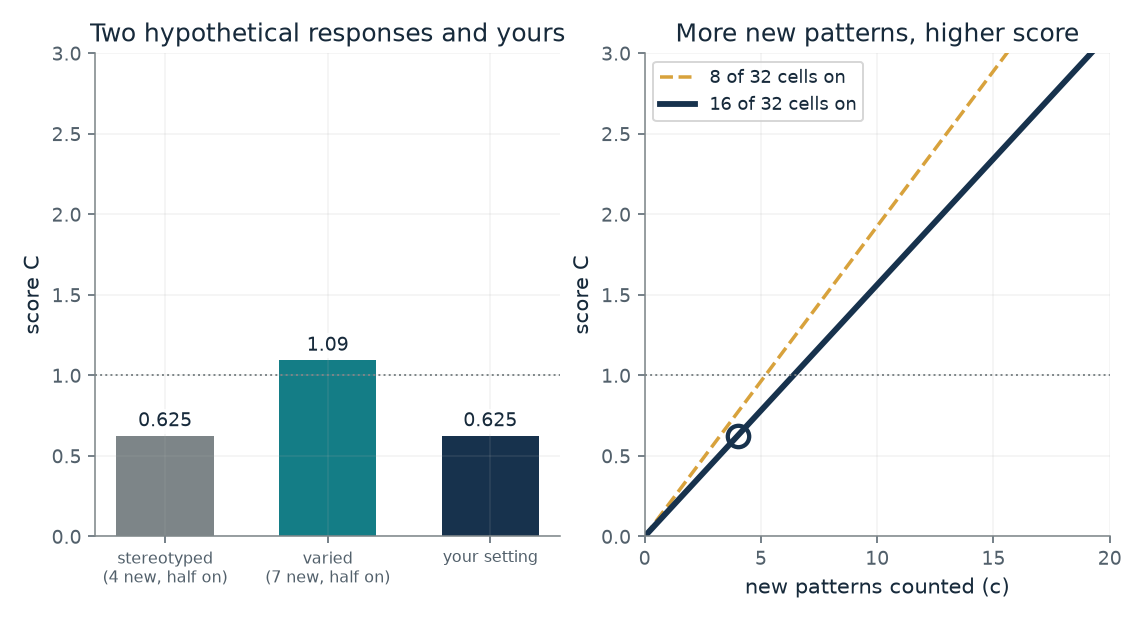

- **Share of cells on:** 0.5
- **Entropy H(p) (bits):** 1
- **Score C:** 0.625
- **New patterns for a score of 1:** 6.4

With 4 new patterns and 16 of 32 cells on, the entropy is 1 bit and the score is 0.625. At this mix, a score of 1 would take 6.4 new patterns.

p = 16/32 = 0.5, H(p) = 1 bit. C = c log2(n) / (n H(p)) = 4 x 5 / (32 x 1) = 0.625. The score is 1 when c = 32 x 1 / 5 = 6.4.

In [2]:
figure, values, explanation = pci_picture(**{'new_patterns': 4, 'on_cells': 16})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does a count of new patterns become a score?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At New patterns counted (c) = 7, Cells that are on, out of 32 = 16: With half the cells on the entropy is 1 bit, and the score is 7 x 5 / 32 = 1.09, the chapter's 'about 1.1'. Four patterns at the same mix gives 0.625. Set on cells to 0 to see an undefined score.

**Takeaway:** More new patterns raise the score, and a lopsided mix of ones and zeros lowers the entropy in the denominator, which raises the score for the same count.

**Why it matters:** A single number from a recording hides the counting rules behind it. Knowing the formula shows what moves the number and where it stops being defined.

**In brains and behavior:** The index is computed from EEG responses to magnetic pulses, with grid entries marked on or off for significant activity. The entries are not individual neurons, and the cutoff the chapter reports, 0.31, is an operational threshold, not a boundary found in nature.

**In machines:** The formula can be applied to any binary string, including a machine's activity. No such score has been validated against reports of experience for any machine, so the arithmetic carries no claim about one.

**Where it applies:** Cells are binary, the string is long enough for the normalization to make sense (the chapter says short strings can score above 1), and p is strictly between 0 and 1. The score is an index of a recorded response, not a measure of experience.

**Check your understanding:** A response of 32 cells has 6 new patterns and 8 cells on. Find the entropy and the score.

<details><summary>Show the answer</summary>

p = 8/32 = 0.25 and H = 0.811 bits. C = 6 x 5 / (32 x 0.811) = 1.16.

</details>

*Source: Chapter 32, Nine of 43 patients with only reflexive behavior gave complex responses to magnetic pulses. Book formulas (the index of Casali and colleagues, as the chapter presents it). The two pattern counts, 4 and 7, are the chapter's hypothetical examples, not patient data and not counted from specified strings. The count c is typed in here; some combinations of c and p could not occur in a real 32-cell string.*

## C32-D02: Why divide by what a random string would need?

How do real counts of new patterns behave for random strings of different lengths, and for a string that just repeats?

The Lempel-Ziv count grows with the length of the string even for pure noise, so a raw count could not tell structure from randomness. Dividing by the count a random string with the same mix would need gives noise a score near 1 and repetition a score below it. Short strings do not follow the large-string rule closely, so their scores overshoot.

$$
C=\frac{c_L\,\log_2 n}{n\,H(p)},\qquad c_L\approx\frac{n\,H(p)}{\log_2 n}\ \text{for long random strings}
$$

**Symbols:** c_L: the Lempel-Ziv count of new patterns, found by the exhaustive parse of the string; n: string length in cells; p: the string's share of cells that are on; C: the score; near 1 for a long random string

**Predict before looking:** Predict whether random 32-cell strings average a score below 1, near 1 or above 1, and whether a string that repeats a fixed rhythm scores higher or lower than they do.

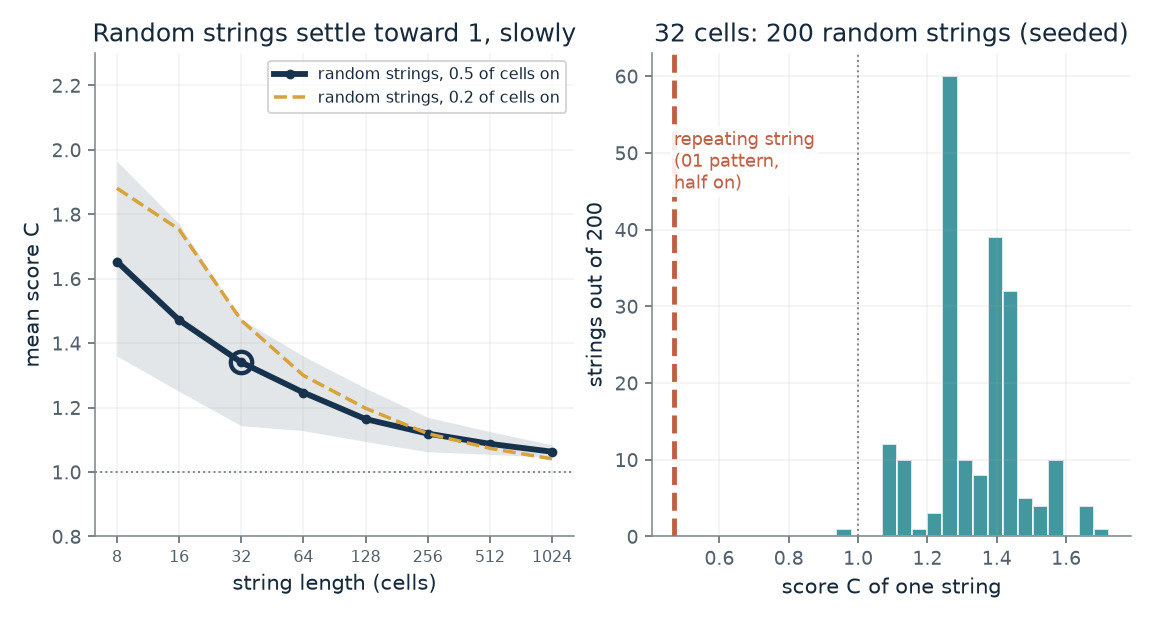

- **Mean score, random strings:** 1.34
- **Middle 80 percent of scores:** 1.14 to 1.47
- **Score of a repeating string:** 0.469
- **Share of random strings scoring above 1:** 0.995

At 32 cells with a chance 0.5 that a cell is on, 200 seeded random strings average a score of 1.34; the repeating string, with 0.5 of its cells on, scores 0.469. Short random strings score above 1, and the average falls toward 1 only slowly as strings lengthen.

Each string: c = Lempel-Ziv count of new patterns, p = its share of ones, C = c log2(32) / (32 x H(p)). Seeds are fixed by length and mix. The repeating string is 01 repeated to 32 cells (its share of ones is 0.5, exactly 0.5).

In [3]:
figure, values, explanation = lz_picture(**{'length': 32, 'share': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why divide by what a random string would need?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At String length (cells) = 32, Chance a cell is on = 0.5: Random 32-cell strings average about 1.34, above 1, which fits the chapter's warning about short strings. The repeating string 0101... scores 0.469. At 1024 cells the random average has fallen only to about 1.06 while the repeating string scores 0.029.

**Takeaway:** For strings of a reasonable length the division makes repetition score far below noise, but short random strings overshoot 1 and the approach to 1 is slow.

**Why it matters:** A cutoff on a score means little if the score depends on string length. Knowing how the benchmark behaves for noise tells a reader what a high or low score does and does not rule out.

**In brains and behavior:** In the chapter's index, noise and muscle activity are meant to be kept from inflating the score by this normalization. This simulation uses random bits only; it is not a model of EEG.

**In machines:** A machine's binary activity can be scored the same way. The normalization behaves the same for any binary string, which says nothing about experience.

**Where it applies:** Strings are independent random bits with a fixed chance of a one, which is a toy stand-in for noise. Strings with no mix of ones and zeros are skipped (their score is undefined). The spread shown is the middle 80 percent of 200 seeded strings, not a confidence interval. At very short lengths the repeating string need not score lower: at 8 cells with a 0.2 chance of a one, it scores above the random average. That repeating 00001 string has only 1 of 8 cells on (a share of 0.125, not 0.2), so its score is not comparable with random strings at a share of 0.2; its share is 0.1875 at 16 to 64 cells and near 0.2 only at long lengths.

**Check your understanding:** In the left panel, does the mean score for 8-cell random strings sit above or below the mean for 1024-cell strings, at a mix of half the cells on?

<details><summary>Show the answer</summary>

Above. The mean is about 1.65 at 8 cells and about 1.06 at 1024 cells, so scores from short strings are not comparable with scores from long ones.

</details>

*Source: Chapter 32, Nine of 43 patients with only reflexive behavior gave complex responses to magnetic pulses. Simulation by the companion, with disclosed seeds, 200 random strings per setting. The chapter states that the normalization approaches 1 for long random strings and that short strings can score above 1; it does not give these simulated values. The count is the Lempel-Ziv 1976 exhaustive parse that the chapter's source note names. No patient data are used.*

## C32-D03: What do the reported counts say, and how much doubt do they carry?

How large are the shares behind the chapter's three reported studies, and how different are their sample sizes?

A share such as 9 of 43 is one sample of a possibly different true rate, and a different sample could have given a somewhat different share. The Wilson interval shows how far a share could move under simple sampling noise. Bigger groups give narrower intervals. The interval cannot correct for how people were chosen, how a diagnosis was made or what a test misses.

$$
\hat p=\frac{k}{n},\qquad \text{Wilson interval}=\frac{\hat p+\frac{z^2}{2n}\pm z\sqrt{\frac{\hat p(1-\hat p)}{n}+\frac{z^2}{4n^2}}}{1+\frac{z^2}{n}}
$$

**Symbols:** k, n: the reported count and the group size; p-hat: the share k divided by n; z: 1.645, 1.96 or 2.576 for 90, 95 or 99 percent

**Predict before looking:** Predict which of the six reported shares has the widest interval, before changing the study or the level.

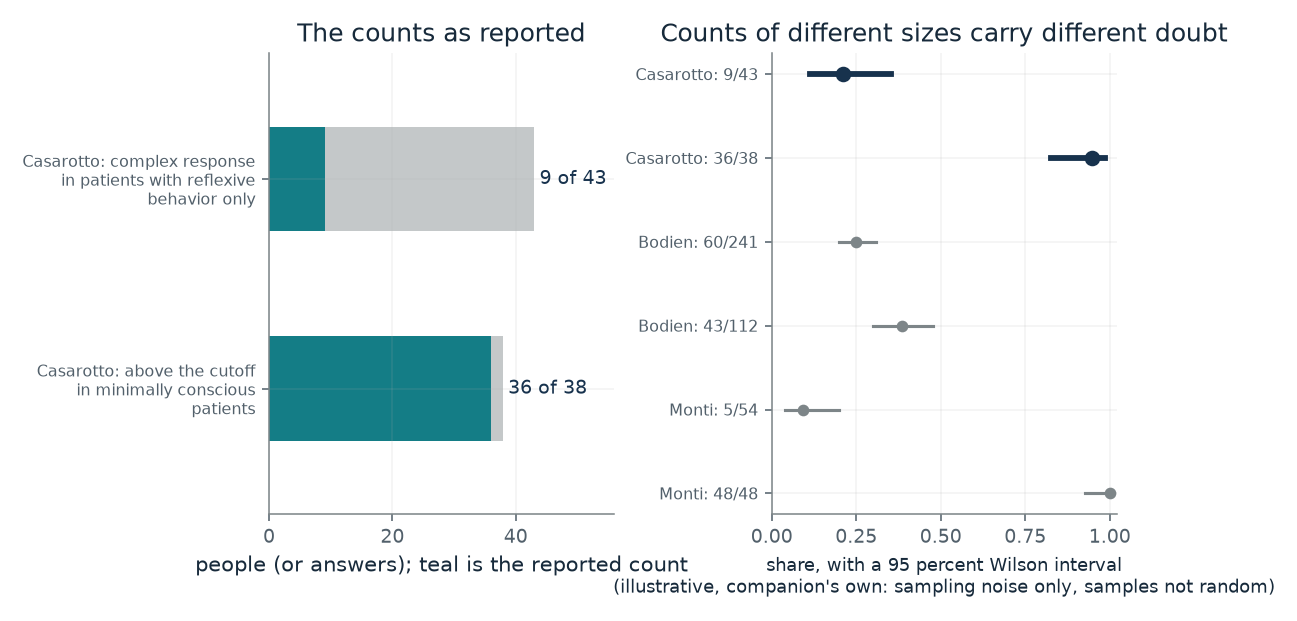

- **Share, Casarotto: 9/43:** 0.209
- **Interval, Casarotto: 9/43:** 0.114 to 0.352
- **Share, Casarotto: 36/38:** 0.947
- **Interval, Casarotto: 36/38:** 0.827 to 0.985

Casarotto: 9/43 is a share of 0.209 with an interval of 0.114 to 0.352; Casarotto: 36/38 is 0.947, interval 0.827 to 0.985. The interval is the companion's own and covers sampling noise only, under an independence assumption these samples do not meet.

Wilson interval at z = 1.96: centre (p + z^2/2n)/(1 + z^2/n), half-width z sqrt(p(1-p)/n + z^2/4n^2)/(1 + z^2/n). For 9 of 43: p = 0.209, interval 0.114 to 0.352. For 36 of 38: p = 0.947, interval 0.827 to 0.985.

In [4]:
figure, values, explanation = counts_picture(**{'study': 'Casarotto and colleagues', 'level': 0.95})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What do the reported counts say, and how much doubt do they carry?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Study = Monti and colleagues, Interval level = 0.95: The 5 of 54 and the 48 of 48 sit at opposite ends of the scale. The 48 of 48 is a share of 1, yet its 95 percent interval reaches down to about 0.93: a perfect record is not a proof of perfection.

**Takeaway:** Shares from small groups carry wide intervals, and a count of 48 of 48 still leaves room below 1. The studies could not show what any group experienced.

**Why it matters:** The chapter's argument depends on counts such as 9 of 43 and 60 of 241. Seeing how large the groups are shows how much weight a share can bear, and what the studies did not report.

**In brains and behavior:** Each share counts people whose recorded responses met a study's rule. A response is a pattern in a scan or EEG, not a report of experience, and the counts do not show what any person experienced.

**In machines:** No machine appears in these counts. The chapter says no test of experience has been validated against reports for any machine.

**Where it applies:** The intervals treat each person or answer as an independent draw from one population with a fixed share. These samples were not random: Bodien's was a convenience sample, the 48 answers came from 16 volunteers, and the groups differ in diagnosis, centre and method. The interval therefore describes sampling noise under that assumption only.

**Check your understanding:** Which has the wider 95 percent interval, 9 of 43 or 60 of 241, and why?

<details><summary>Show the answer</summary>

9 of 43 spans about 0.11 to 0.35, a width of 0.24, and 60 of 241 spans about 0.20 to 0.31, a width of 0.11. The larger group gives the narrower interval.

</details>

*Source: Chapter 32, Only 43 of 112 who followed commands at the bedside also responded on fMRI or EEG. Counts quoted from the chapter: Casarotto and colleagues (9 of 43 with a complex response; 36 of 38 minimally conscious patients above the 0.31 cutoff), Bodien and colleagues (60 of 241 and 43 of 112, a convenience sample of 353 adults), Monti and colleagues (5 of 54 who could modulate brain activity; 48 of 48 healthy answers decoded). The Wilson intervals are the companion's own, not reported by any study.*

## C32-D04: How fast does a theory's score become impossible to compute?

Rings of simple gates took about 1 second, 16 seconds and 2.75 hours as they grew from 3 to 5 to 7 gates. What does that say about a system as large as a brain?

The score depends on trying many ways to cut the system into parts. The number of ways to cut, and the work to evaluate each, grows steeply with the number of nodes. The reported times show that growth for rings of 3, 5 and 7 gates, and the authors put the practical limit at about 10 to 12 nodes.

$$
\text{cost}(n)\sim n^{5}\,3^{n}
$$

**Symbols:** n: the number of nodes (gates) in the system; cost(n): the order of the algorithm's work, in relative units; it is not a number of seconds

**Predict before looking:** Predict how many times longer 7 gates took than 5 gates, given that 5 gates took about 16 times as long as 3.

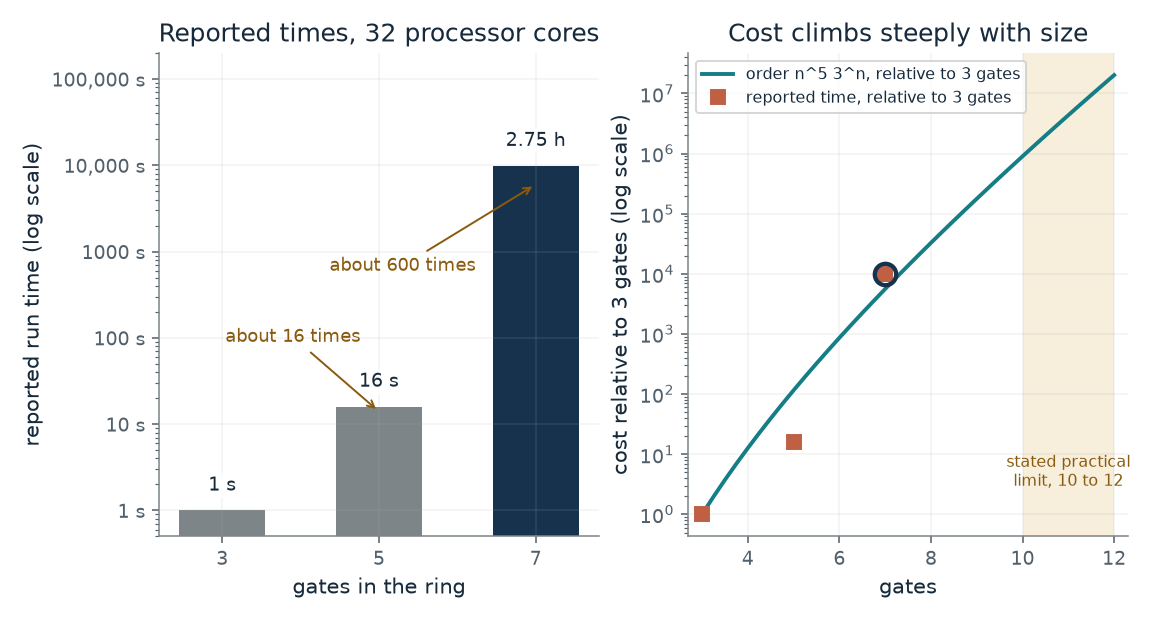

- **Reported time:** 2.75 hours
- **Times longer than the previous ring:** 619
- **Order formula's growth over the previous ring:** 48.4
- **Reported time in seconds:** 9900

A ring of 7 gates took about 2.75 hours, 619 times the 5-gate time. The order formula n^5 3^n gives 48.4 times for the same step, so the formula and the timings differ step by step.

7 gates: 9900 s; 5 gates: 16 s; ratio 619. Formula ratio = (7/5)^5 x 3^(2) = 48.4.

In [5]:
figure, values, explanation = iit_time_picture(**{'gates': 7})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt="How fast does a theory's score become impossible to compute?"))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Gates in the ring = 7: Seven gates took about 2.75 hours, roughly 600 times the 16 seconds for five. The order formula gives only about 48 times for that step, so the two do not track each other step by step.

**Takeaway:** Adding two gates multiplied the time by about 16 and then by about 600, and a brain has billions of neurons, so the score cannot be directly computed there.

**Why it matters:** A test of experience has to be checkable against known cases. A score that cannot be computed for a system of the relevant size cannot be checked there, although other predictions or proxies may still be tested.

**In brains and behavior:** The theory ties experience to integration, and the score asks how much a cut into two parts destroys. This is a theory's quantity computed on a toy system, not a measurement of anyone's experience.

**In machines:** The runs are of software on simple gates. The cost of the algorithm says nothing about whether a machine has experience.

**Where it applies:** Only three ring sizes were reported, on one benchmark family and one machine. An order formula drops constants and says nothing about which times to expect. The comparison of the formula with the timings is the companion's own.

**Check your understanding:** How many times longer did the 7-gate ring take than the 3-gate ring, using the reported times?

<details><summary>Show the answer</summary>

2.75 hours is 9900 seconds, against 1 second, so about 9900 times as long.

</details>

*Source: Chapter 32, A theory's score took 2.75 hours for seven gates. The three run times are those reported for rings of stochastic majority gates on 32 processor cores. The order n^5 3^n and the practical limit of about 10 to 12 nodes are from the chapter's source note on the same paper, which says execution times were substantially variable. The formula gives relative cost only; the companion extrapolates no times.*

## C32-D05: Can two machines give the same answers and be wired differently?

A recurrent adder keeps a running total. An unrolled chain does the same with one unit per input. Do their outputs ever differ?

The recurrent unit feeds its output back into itself at each step, and the chain passes its total forward through separate units. Over a fixed four steps, each step of the loop corresponds to one unit of the chain, so the totals match at every step. The two differ only in how they are built, which behavior cannot show.

$$
h_t=h_{t-1}+x_t,\qquad y=h_4\qquad \text{versus}\qquad y=\big(((x_1)+x_2)+x_3\big)+x_4
$$

**Symbols:** x_t: the input at step t, 0 or 1; h_t: the running total after step t, held by the feedback unit; y: the output, the total after four inputs

**Predict before looking:** For the sequence 1, 0, 1, 1, predict the output of each wiring, and whether any of the 16 sequences makes them differ.

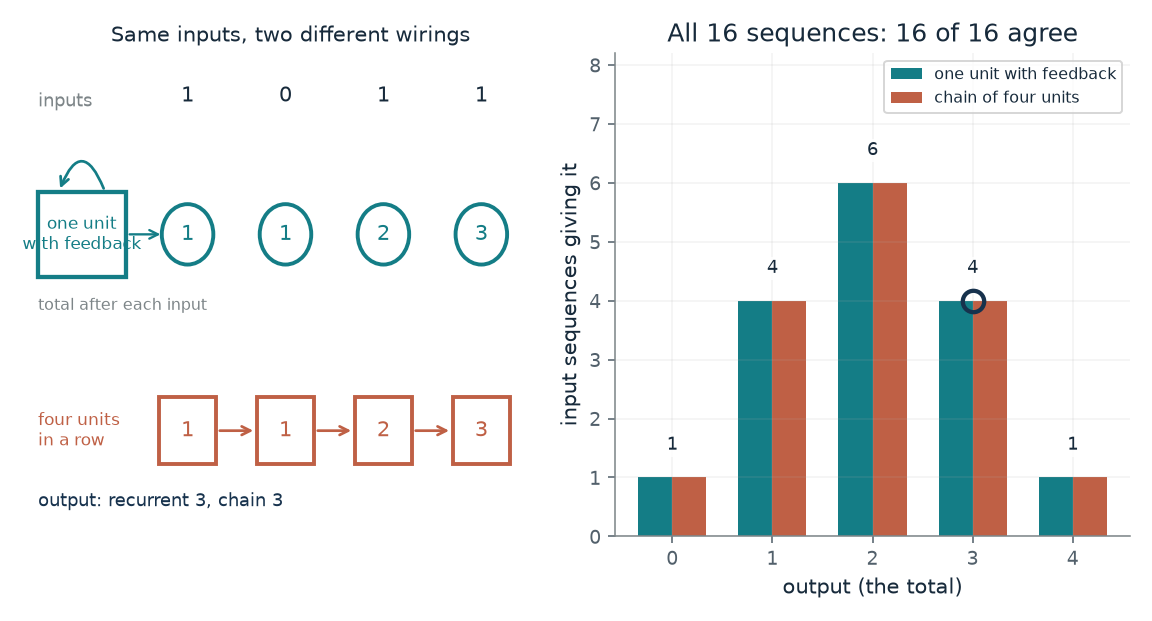

- **Inputs:** 1 0 1 1
- **Output, one unit with feedback:** 3
- **Output, chain of four:** 3
- **Sequences where they agree:** 16 of 16

For inputs 1 0 1 1 the feedback unit's total runs 1, 1, 2, 3 and the chain gives the same, ending at 3. The two agree on all 16 of 16 sequences, yet one has a single unit and a feedback wire and the other has four units in a row.

Recurrent: state = state + input, giving 1, 1, 2, 3. Unrolled: unit k adds input k to the total from unit k - 1, giving 1, 1, 2, 3. The outputs 3 and 3 match; so do the other 15 sequences.

In [6]:
figure, values, explanation = unfolding_picture(**{'sequence': 11})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Can two machines give the same answers and be wired differently?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Input sequence (binary number, first input is the leading bit) = 11: Sequence 11 is the chapter's 1, 0, 1, 1. Both versions give 3, with totals 1, 1, 2, 3. Try any other sequence: the outputs never differ, though one design has one unit and a feedback wire and the other has four units in a row.

**Takeaway:** Identical outputs on every input do not reveal the wiring, so a theory that ties experience to wiring cannot be tested by behavior alone, which is the point of the argument.

**Why it matters:** If a machine's words about itself came from one circuit or the other, the words alone would not say which. The chapter treats matching behavior as weak evidence about a system's insides.

**In brains and behavior:** The unfolding argument applies to theories that tie experience to a system's internal causal structure. Critics replied that measurements of brain activity can still test them.

**In machines:** Both adders are exact specifications, not models of behavior. A talking machine's replies would be like these outputs: the same whichever circuit produced them.

**Where it applies:** A fixed number of steps, binary inputs and a readout that reports the total. The equivalence holds over the fixed number of steps; it is a statement about this toy, not a proof about brains or about any real model.

**Check your understanding:** For inputs 0, 1, 1, 0, what are the running totals and the output of each wiring?

<details><summary>Show the answer</summary>

The totals are 0, 1, 2, 2 and both wirings output 2.

</details>

*Source: Chapter 32, Same outputs, different insides: what a matching machine does and does not show. The chapter's constructed toy, which the source note says is not in the cited paper: inputs 1, 0, 1, 1 give totals 1, 1, 2, 3, and the two versions agree on all 16 input sequences. The unfolding argument itself is Doerig and colleagues (2019); critics replied that brain measures can still test such theories.*

## C32-D06: How much does a negative leave open?

A test flags some share of cases and catches some share of those with the property. What share of its negatives still has the property?

The flagged cases are a share r of all cases, and they are a share s of the cases that have the property, so the property is in r / s of all cases. The rest of those, r / s - r, were not flagged, and they all sit among the 1 - r negatives. Dividing gives the formula. A low sensitivity makes the property common among the negatives.

$$
m=\frac{r\,(1-s)}{s\,(1-r)}
$$

**Symbols:** r: the flag rate: the share of all cases the test marks positive; 0 < r < 1; s: the sensitivity: the share of cases with the property that the test catches; s above 0 and at least r; m: the share of negatives that have the property

**Predict before looking:** At a flag rate of 0.1 and a sensitivity of 0.5, predict how many of the 90 negatives out of 100 still have the property.

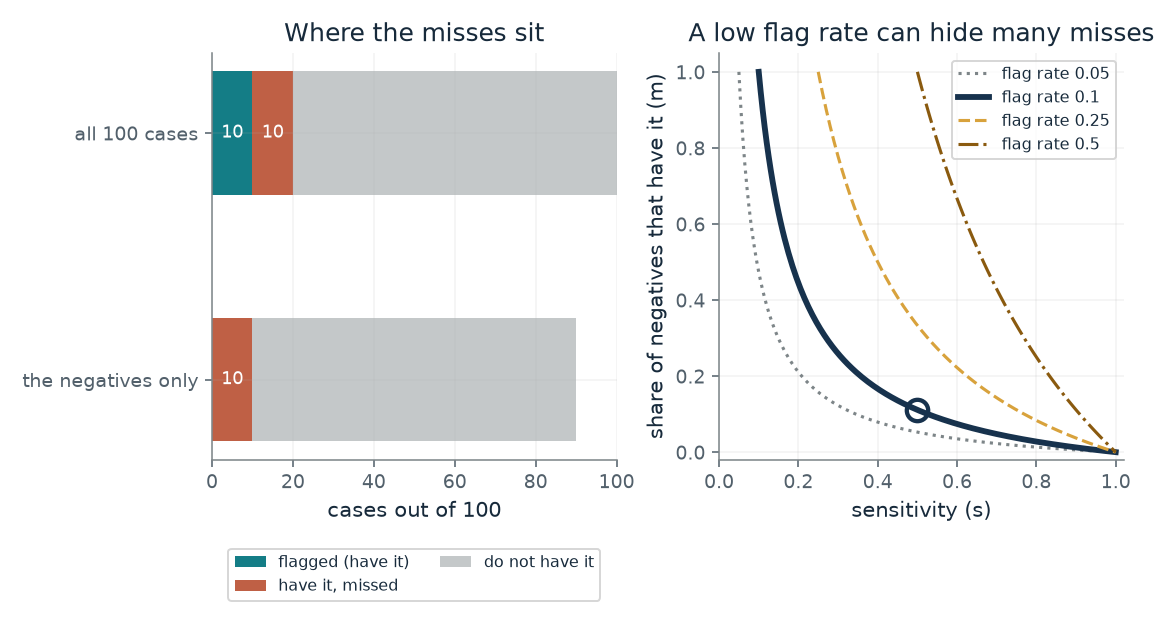

- **Cases with the property (of 100):** 20
- **Missed by the test:** 10
- **Negatives:** 90
- **Share of negatives that have it (m):** 0.111

A test that flags 10 of 100 cases and catches a share 0.5 of the cases with the property must meet 20 such cases, so it misses 10, all among its 90 negatives. That is a share m of 0.111.

With the property: r / s = 0.1 / 0.5 = 0.2 of all cases. Missed = r/s - r = 0.1. m = r(1 - s) / (s(1 - r)) = 0.1 x 0.5 / (0.5 x 0.9) = 0.111.

In [7]:
figure, values, explanation = miss_picture(**{'flag_rate': 0.1, 'sensitivity': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much does a negative leave open?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Flag rate (r) = 0.1, Sensitivity (s) = 0.5: Twenty cases have the property and 10 are flagged, so 10 are missed among the 90 negatives: m = 10/90 = 0.111. Raise the flag rate to 0.25 with a low sensitivity and the negatives become much less reassuring.

**Takeaway:** A negative result cannot be read without the test's sensitivity. A modest flag rate with a modest sensitivity can leave a large share of the negatives with the property.

**Why it matters:** A silent scan is not an empty answer. The chapter's patients with no bedside response were flagged at about a quarter on fMRI or EEG, and without a sensitivity the miss rate cannot be stated.

**In brains and behavior:** A brain-based task that finds no response means only that the task found no response. Bodien's counts show tasks missing responses that were already observable at the bedside.

**In machines:** A detector of some property in a model's activity has the same bookkeeping. A negative result is only as informative as the detector's measured sensitivity.

**Where it applies:** The test never flags a case that lacks the property (no false positives), s is above zero, r is between zero and one, and r is no larger than s. The formula describes an assumed detector, not a measured property of any real test or machine.

**Check your understanding:** A test flags 25 of 100 cases and catches 90 percent of the cases with the property. What share of its negatives have the property?

<details><summary>Show the answer</summary>

m = 0.25 x 0.1 / (0.9 x 0.75) = 0.037, about 4 percent. With a sensitivity of 0.5 instead, m would be 0.333.

</details>

*Source: Chapter 32, Only 43 of 112 who followed commands at the bedside also responded on fMRI or EEG. Book formula. The 100-case detector with 10 flagged and half caught is the chapter's constructed illustration, not patient counts. The flag rate of 0.25 matches the chapter's reading of 60 of 241 (about 0.25); the paper reports no sensitivity for that group, so the miss rate for those patients is unknown.*

## C32-D07: What does 48 of 48 correct leave open?

A decoding method read 48 of 48 answers from healthy volunteers correctly, and 5 of 5 decodable answers from one patient. Does a perfect record mean a perfect method?

If each answer is right with chance a, all k are right with chance a to the power k. For 48 answers this falls quickly as a drops, but it stays above 5 percent down to about 0.94. So, if answers were independent, the record rules out a per-answer error above about 6 percent at the 5 percent level; it does not show the error rate is zero.

$$
P(\text{all } k\text{ correct})=a^{k},\qquad a_{5\%}=0.05^{1/k}
$$

**Symbols:** a: the chance that any one answer is decoded correctly; k: the number of answers, all correct (5 or 48); a_5%: the lowest accuracy for which a perfect record still has at least a 5 percent chance

**Predict before looking:** Predict the lowest per-answer accuracy that would still give 48 of 48 at least one time in twenty.

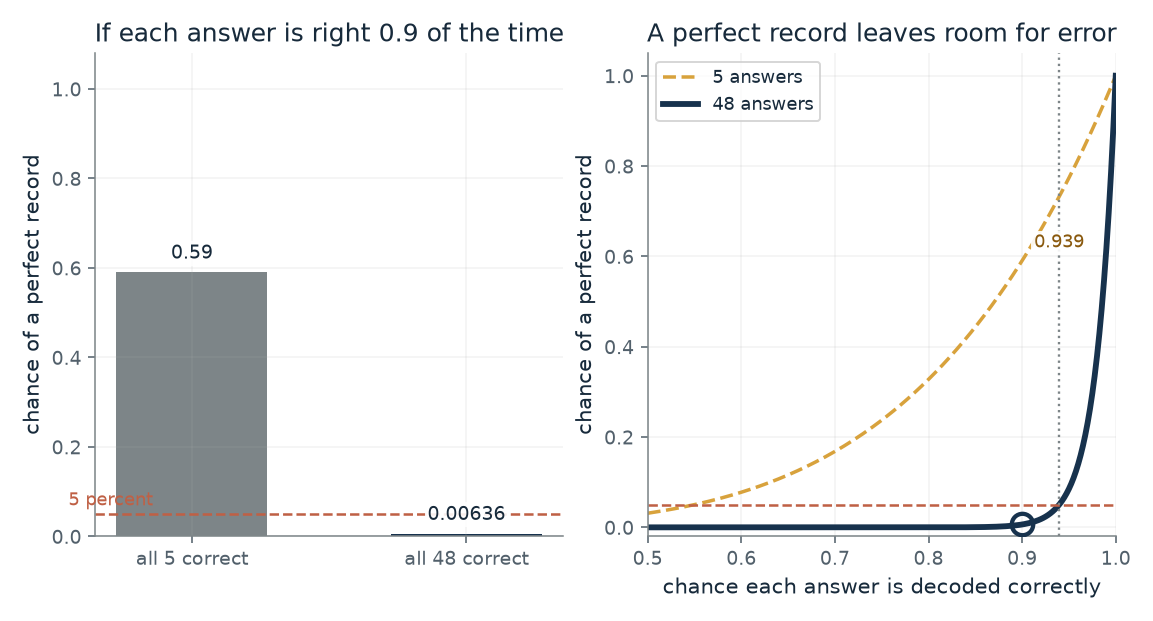

- **Chance all answers are correct:** 0.00636
- **Expected wrong answers:** 4.8
- **Lowest accuracy still giving this record 5 percent of the time:** 0.939
- **Answers in the record:** 48

If each of 48 answers were right with chance 0.9, a perfect record would come up 0.00636 of the time. A perfect record at 5 percent or more is consistent with any accuracy from 0.939 up, so it does not show the method is perfect.

P(all 48 correct) = 0.9^48 = 0.00636. The accuracy a at which a^48 = 0.05 is 0.05^(1/48) = 0.939.

In [8]:
figure, values, explanation = all_correct_picture(**{'accuracy': 0.9, 'answers': 48})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does 48 of 48 correct leave open?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Chance each answer is correct = 0.95, Answers in the record = 48: At 0.95 a perfect record of 48 comes up about 8.5 percent of the time. The accuracy at which it falls to 5 percent is about 0.94, so a method with 6 percent errors would still show a perfect record about one time in twenty.

**Takeaway:** A short perfect record is compatible with a method that makes occasional errors, and a record of 5 leaves room for much more.

**Why it matters:** The chapter leans on the 48 of 48 behind the yes in the scanner. Seeing how much accuracy that record excludes shows how strong the evidence is, and that it supports an answer about a name, not what the patient felt.

**In brains and behavior:** The decoder compared each scan with two reference scans. A correct decoding of a yes-or-no question about a name is a match to a checkable fact, not evidence of what the patient experienced.

**In machines:** Any classifier with a short perfect record has the same limit: a perfect record shows low error only up to what the number of trials can resolve.

**Where it applies:** Each answer is correct independently with the same chance a. That is a simplification: the 48 answers came from 16 volunteers, three each, and the patient's answers came from one person. The calculation does not estimate the method's real accuracy.

**Check your understanding:** A method is right 90 percent of the time per answer. How likely is a perfect record of 5, and of 48?

<details><summary>Show the answer</summary>

0.9^5 = 0.59, so a perfect record of 5 is likely. 0.9^48 = 0.0064, so a perfect record of 48 would be rare at that accuracy.

</details>

*Source: Chapter 32, Tennis for yes: what a scan needs before it can be an answer. The counts 48 of 48 (16 healthy volunteers, 48 questions) and 5 of 5 decodable patient answers are the chapter's. The probability calculation is the companion's own and is not in the chapter or the paper.*

## Bring it to your own question

Ask what the signal is, what ties it to reports of experience in known cases, whether the tie transfers to the new case, and which rival explanations were tested. For a negative result, ask for the test's sensitivity before reading the silence. For a score, ask how its cutoff was chosen. For a machine, say that no test of experience has been validated against reports for any machine.

Use the `mmi-ch32-question-experience` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.